# P2.12 — Mortgage credit, household debt and the price cycle

**Questions:** RQ9.2 (rates, mortgage lending, household debt and prices; `p2_08` covered the rates), RQ9.3 (did credit
availability shape access to ownership?). Companion of `p2_08` and `p2_09`.

National quarterly series, 2007 Q4 to 2026 Q2: the stock of household loans for house purchase and total household debt
(Banco de Portugal, domain 18, all lenders), against the BIS real and nominal house price index. Both are deflated with the
price index's own deflator. Lending standards (loan-to-value, maturity, income multiples) are not available, so this
describes how much credit there was, not how easy it was to get. Association in time only, two credit regimes in 18 years.

In [1]:
import pandas as pd

from pthousing.analysis import credit, macro
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
frame = credit.quarterly_frame(interim.read("bis_spp"), interim.read("bp_household_debt"))
changes = credit.add_changes(frame)
print(
    f"{frame.index.min():%Y}-Q{frame.index.min().quarter} to {frame.index.max():%Y}-Q{frame.index.max().quarter}, {len(frame)} quarters"
)

2007-Q4 to 2026-Q1, 74 quarters


## Step 1 — Episodes
Boundaries come from the credit and price series, not from an outcome: the peak of the real housing-loan stock, the low of
the real price index after it, the low of the real loan stock, and the last quarter.

In [2]:
loans, price = frame["housing_loans_real_eur_m"], frame["hpi_real_b2010"]
peak = loans.idxmax()
price_low = price.loc[peak:].idxmin()
loans_low = loans.loc[price_low:].idxmin()
q = lambda t: f"{t.year}Q{t.quarter}"  # noqa: E731
first, last = q(frame.index[0]), q(frame.index[-1])
windows = {
    "credit still growing": (first, q(peak)),
    "crisis and troika": (q(peak), q(price_low)),
    "prices recover, credit shrinks": (q(price_low), q(loans_low)),
    "credit revives": (q(loans_low), last),
}
epis = credit.episodes(frame, windows)
style.save_table(epis.round(1).reset_index(names="episode"), "p2", "credit_episodes")
style.save_table(frame.round(2).reset_index(), "p2", "credit_quarterly")
epis.round(1)

,start,end,real_price_change_pct,nominal_price_change_pct,loans_real_change_pct,loans_nominal_change_pct,loans_per_price_change_pct,loans_gdp_change_pp,debt_income_start_pct,debt_income_end_pct
credit still growing,2007Q4,2010Q1,-5.8,-5.0,6.3,7.2,12.9,4.1,110.1,111.3
crisis and troika,2010Q1,2013Q2,-21.3,-14.4,-13.6,-6.1,9.8,-0.8,111.3,109.1
"prices recover, credit shrinks",2013Q2,2024Q2,98.2,139.3,-27.2,-12.1,-63.3,-32.5,109.1,70.8
credit revives,2024Q2,2026Q1,28.5,31.8,11.9,14.8,-12.9,1.0,70.8,72.4


## Step 2 — Which comes first, price growth or credit growth?
Correlation of a year's real price growth with housing-loan growth (transactions-based, so write-offs and sales of loans do not
count) shifted by each lag. A positive lag is credit growth that came earlier, a negative lag credit growth that came later.
With overlapping annual changes there is about one independent observation a year, so the band is wide.

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
lag_quarters,-8.00,-7.00,-6.00,-5.00,-4.00,-3.00,-2.00,-1.00,0.00,1.00,...,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.00
corr,0.49,0.48,0.49,0.50,0.52,0.52,0.49,0.44,0.36,0.28,...,0.02,-0.13,-0.26,-0.36,-0.41,-0.43,-0.42,-0.38,-0.34,-0.30
band,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47,...,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47,0.47


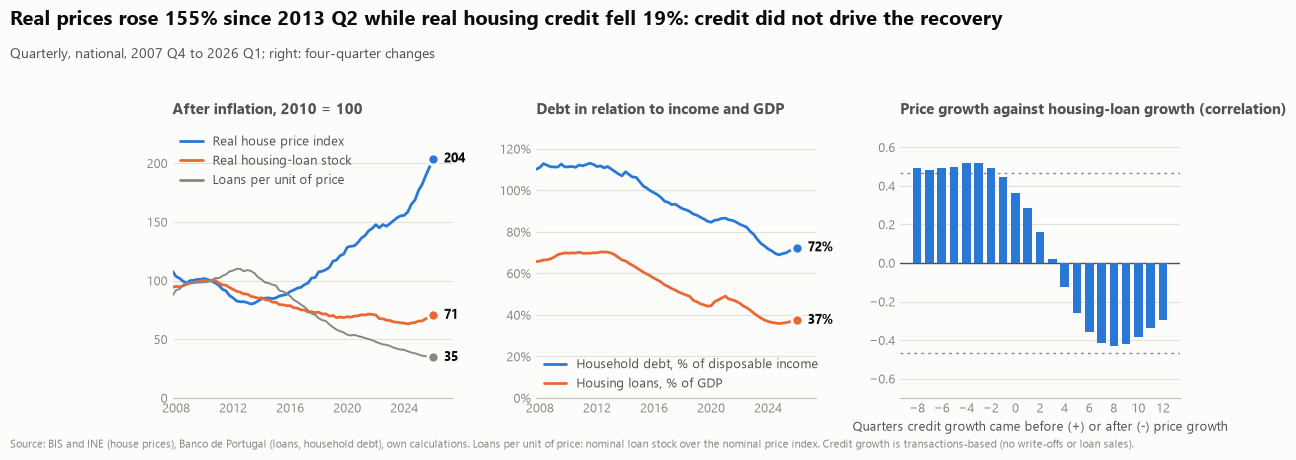

In [3]:
profile = macro.lag_profile(changes, "growth_real_pct", credit.GROWTH_COLUMN, range(-8, 13))
fig = charts.credit_and_prices(frame, profile)
style.save_fig(fig, "p2", "credit_and_prices")
style.save_table(profile.round(3), "p2", "credit_lag_profile")
profile.round(2).T

## Step 3 — A pre-specified timing test
As in `p2_08`: price growth over a year on credit growth over the year before (the lag equals the window, so the two do not
overlap), Newey-West errors. Added in turn: last year's price growth (momentum), a placebo (credit growth of the year *after*),
the same year, the stock in real terms instead of the flow, and the two halves of the sample. A credit fall that precedes a
price rise is a regime pattern (credit shrank in 2011-2019 while prices recovered), not evidence that credit cuts prices.

In [4]:
specs = {
    "credit growth a year earlier": {},
    "+ last year's price growth": {"own_lag": True},
    "+ placebo: next year's credit growth": {"own_lag": True, "lead": True},
    "same year": {"lag": 0},
    "real stock instead of flow": {"x_col": "loans_real_growth_pct", "own_lag": True},
    "2008-2015": {"own_lag": True, "sample": ("2008", "2015")},
    "2016-2026": {"own_lag": True, "sample": ("2016", "2026")},
}
timing = pd.DataFrame({k: credit.credit_timing(changes, **v) for k, v in specs.items()}).T
style.save_table(timing.round(3).reset_index(names="specification"), "p2", "credit_timing")
timing.round(3)

,coef_pct_per_pp,ci_low,ci_high,p_value,r2,n,own_lag_coef,lead_coef_pct_per_pp,lead_p_value
credit growth a year earlier,-0.297,-1.141,0.547,0.490,0.016,66.0,NaN,NaN,NaN
+ last year's price growth,-0.587,-1.229,0.055,0.073,0.542,66.0,0.767,NaN,NaN
+ placebo: next year's credit growth,-0.932,-1.541,-0.322,0.003,0.715,62.0,0.495,0.8,0.003
same year,0.707,-0.029,1.444,0.060,0.133,70.0,NaN,NaN,NaN
real stock instead of flow,-0.579,-1.157,-0.000,0.050,0.551,66.0,0.788,NaN,NaN
2008-2015,-0.947,-2.076,0.182,0.100,0.346,25.0,0.322,NaN,NaN
2016-2026,-0.317,-0.940,0.307,0.320,0.113,41.0,0.340,NaN,NaN


## Key numbers

In [5]:
e = epis
for name, row in e.iterrows():
    print(
        f"{name} {row['start']}-{row['end']}: real price {row['real_price_change_pct']:+.0f}%, real housing loans "
        f"{row['loans_real_change_pct']:+.0f}% (nominal {row['loans_nominal_change_pct']:+.0f}%), loans per unit of price "
        f"{row['loans_per_price_change_pct']:+.0f}%, loans/GDP {row['loans_gdp_change_pp']:+.1f} pp, debt/income "
        f"{row['debt_income_start_pct']:.0f}% to {row['debt_income_end_pct']:.0f}%"
    )
f0, f1 = frame.iloc[0], frame.iloc[-1]
print(
    f"{first} to {last}: housing loans {f0['housing_loans_gdp_pct']:.0f}% to {f1['housing_loans_gdp_pct']:.0f}% of GDP, "
    f"household debt {f0['household_debt_income_pct']:.0f}% to {f1['household_debt_income_pct']:.0f}% of disposable income, "
    f"nominal housing loans €{f0['housing_loans_stock_eur_m'] / 1000:.0f}bn to €{f1['housing_loans_stock_eur_m'] / 1000:.0f}bn, "
    f"real price {100 * (f1['hpi_real_b2010'] / f0['hpi_real_b2010'] - 1):+.0f}%"
)
band = profile["band"].iloc[0]
print(
    "lags outside the band:",
    profile.loc[profile["corr"].abs() > band, ["lag_quarters", "corr"]].round(2).to_dict("records"),
)
for name, row in timing.iterrows():
    extra = (
        f", placebo {row['lead_coef_pct_per_pp']:+.2f} (p={row['lead_p_value']:.2f})"
        if pd.notna(row.get("lead_coef_pct_per_pp"))
        else ""
    )
    print(
        f"{name}: {row['coef_pct_per_pp']:+.2f} points per pp [{row['ci_low']:+.2f}, {row['ci_high']:+.2f}], p={row['p_value']:.2f}, n={int(row['n'])}{extra}"
    )

credit still growing 2007Q4-2010Q1: real price -6%, real housing loans +6% (nominal +7%), loans per unit of price +13%, loans/GDP +4.1 pp, debt/income 110% to 111%
crisis and troika 2010Q1-2013Q2: real price -21%, real housing loans -14% (nominal -6%), loans per unit of price +10%, loans/GDP -0.8 pp, debt/income 111% to 109%
prices recover, credit shrinks 2013Q2-2024Q2: real price +98%, real housing loans -27% (nominal -12%), loans per unit of price -63%, loans/GDP -32.5 pp, debt/income 109% to 71%
credit revives 2024Q2-2026Q1: real price +28%, real housing loans +12% (nominal +15%), loans per unit of price -13%, loans/GDP +1.0 pp, debt/income 71% to 72%
2007Q4 to 2026Q1: housing loans 66% to 37% of GDP, household debt 110% to 72% of disposable income, nominal housing loans €115bn to €117bn, real price +89%
lags outside the band: [{'lag_quarters': -8, 'corr': 0.49}, {'lag_quarters': -7, 'corr': 0.48}, {'lag_quarters': -6, 'corr': 0.49}, {'lag_quarters': -5, 'corr': 0.5}, {'lag_quarters